# Gradient Descent: Batch, Stochastic, and Mini-Batch
For the loss $L(\theta)=\frac{1}{2n}\lVert X\theta-y\rVert^2$, the full gradient is $\nabla L(\theta)=\frac{1}{n}X^\top(X\theta-y)$. Each mini-batch uses the corresponding mean gradient.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
print('NumPy:', np.__version__)

NumPy: 1.26.4


## 1. Synthetic linear-regression dataset

Generate $y=3+2x+\varepsilon$ with Gaussian noise

In [5]:
n_samples = 300
x = rng.uniform(-1.5, 1.5, size=n_samples)
noise = rng.normal(0, 0.25, size=n_samples)
y = 3.0 + 2.0 * x + noise
X = np.column_stack([np.ones(n_samples), x])
order = rng.permutation(n_samples)
train_idx, test_idx = order[:240], order[240:]
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]
true_theta = np.array([3.0, 2.0])

def loss(X, y, theta):
    return 0.5 * np.mean((X @ theta - y) ** 2)

def full_gradient(X, y, theta):
    return X.T @ (X @ theta - y) / len(y)

theta_opt = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
print('True parameters: ', true_theta)
print('Least-squares fit:', np.round(theta_opt, 4))
print('Optimal training loss:', round(loss(X_train, y_train, theta_opt), 6))

True parameters:  [3. 2.]
Least-squares fit: [2.9997 1.9985]
Optimal training loss: 0.031065


## 2. Implement the three optimizers

BGD takes one update per epoch, SGD takes $n$ updates and MBGD takes $\lceil n/b\rceil$ updates.

In [42]:
class BGD:
    def __init__(self, lr=0.1, epoch=100, seed=42):
        self.learning_rate = lr
        self.epoch = epoch
        self.seed = seed

    def fit(self, X_train, Y_train):
        X_train = np.asarray(X_train, dtype=float)
        y = np.asarray(Y_train, dtype=float).reshape(-1)
        self.theta = np.zeros(X_train.shape[1])
        self.history = [loss(X_train, y, self.theta)]
        self.updates = 0
        self.samples_processed = 0
        for _ in range(self.epoch):
            nabla = full_gradient(X_train, y, self.theta)
            self.theta -= self.learning_rate * nabla
            self.updates += 1
            self.samples_processed += len(y)
            self.history.append(loss(X_train, y, self.theta))
        return self

    def predict(self, X):
        return np.asarray(X) @ self.theta


class SGD(BGD):
    def fit(self, X_train, Y_train):
        X_train = np.asarray(X_train, dtype=float)
        y = np.asarray(Y_train, dtype=float).reshape(-1)
        self.theta = np.zeros(X_train.shape[1])
        self.history = [loss(X_train, y, self.theta)]
        self.updates = 0
        self.samples_processed = 0
        rng_local = np.random.default_rng(self.seed)
        for _ in range(self.epoch):
            for i in rng_local.permutation(len(y)):
                xi = X_train[i]  # shape (n_features,)
                nabla = xi * (xi @ self.theta - y[i])
                self.theta -= self.learning_rate * nabla
                self.updates += 1
                self.samples_processed += 1
            self.history.append(loss(X_train, y, self.theta))
        return self


class MBGD(BGD):
    def __init__(self, lr=0.1, epoch=100, batch_size=24, seed=42):
        super().__init__(lr=lr, epoch=epoch, seed=seed)
        self.batch_size = batch_size

    def fit(self, X_train, Y_train):
        X_train = np.asarray(X_train, dtype=float)
        y = np.asarray(Y_train, dtype=float).reshape(-1)
        if not 1 <= self.batch_size <= len(y):
            raise ValueError('batch_size must be between 1 and the training-set size')
        self.theta = np.zeros(X_train.shape[1])
        self.history = [loss(X_train, y, self.theta)]
        self.updates = 0
        self.samples_processed = 0
        rng_local = np.random.default_rng(self.seed)
        for _ in range(self.epoch):
            order = rng_local.permutation(len(y))
            for start in range(0, len(y), self.batch_size):
                idx = order[start:start + self.batch_size]
                xb, yb = X_train[idx], y[idx]
                nabla = xb.T @ (xb @ self.theta - yb) / len(idx)
                self.theta -= self.learning_rate * nabla
                self.updates += 1
                self.samples_processed += len(idx)
            self.history.append(loss(X_train, y, self.theta))
        return self

## 3. Fit models and compare with least squares

We use the same learning rate and number of data passes for illustration

In [11]:
epochs = 80
models = {
    'BGD': BGD(lr=0.1, epoch=epochs, seed=SEED),
    'SGD': SGD(lr=0.1, epoch=epochs, seed=SEED),
    'MBGD': MBGD(lr=0.1, epoch=epochs, batch_size=24, seed=SEED),
}
for model in models.values():
    model.fit(X_train, y_train)

rows = []
for name, model in models.items():
    rows.append({
        'Algorithm': name,
        'Intercept': model.theta[0],
        'Slope': model.theta[1],
        'Train loss': loss(X_train, y_train, model.theta),
        'Test loss': loss(X_test, y_test, model.theta),
        'Parameter error vs OLS': np.linalg.norm(model.theta - theta_opt),
        'Updates': model.updates,
        'Samples processed': model.samples_processed,
    })
results = pd.DataFrame(rows).set_index('Algorithm')
print(results.round(5).to_string())

           Intercept    Slope  Train loss  Test loss  Parameter error vs OLS  Updates  Samples processed
Algorithm                                                                                               
BGD          2.99721  1.99162     0.03108    0.03451                 0.00735       80              19200
SGD          3.00424  1.92486     0.03312    0.03462                 0.07379    19200              19200
MBGD         3.00208  1.99842     0.03107    0.03479                 0.00236      800              19200


## 4. Convergence comparison (loss vs epoch)

Each curve reports full dataset training loss at the end of an epoch, even for stochastic methods

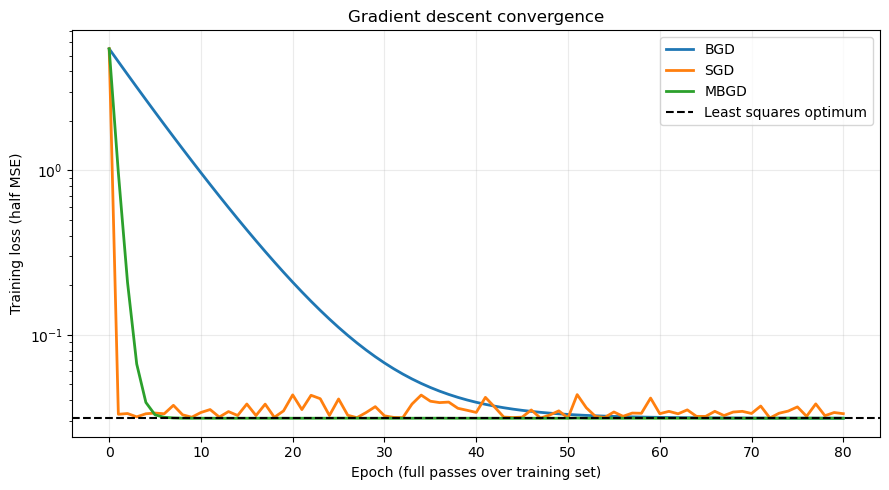

In [36]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, model in models.items():
    ax.plot(range(epochs + 1), model.history, label=name, linewidth=2)
ax.axhline(optimal_loss, color='black', linestyle='--', label='Least squares optimum')
ax.set(xlabel='Epoch (full passes over training set)', ylabel='Training loss (half MSE)', title='Gradient descent convergence')
ax.set_yscale('log')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Fitted lines vs the observed data

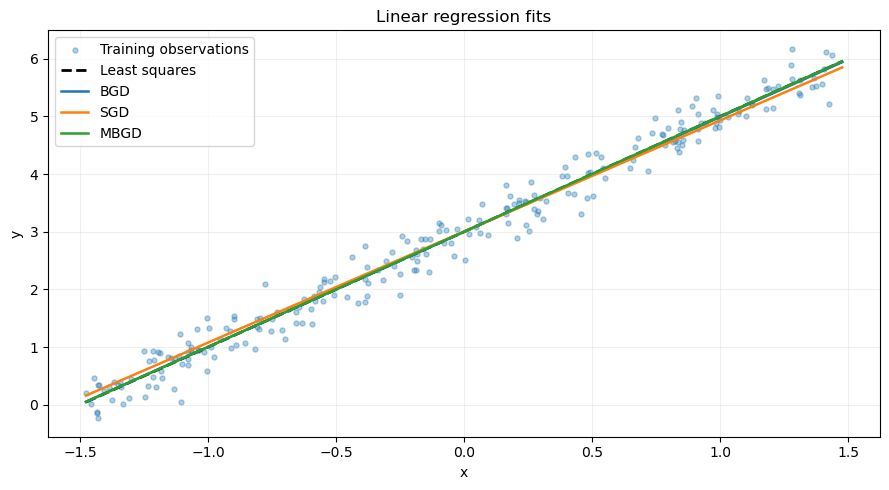

In [20]:
x_line = np.linspace(x.min(), x.max(), 200)
X_line = np.column_stack([np.ones_like(x_line), x_line])
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(X_train[:, 1], y_train, s=13, alpha=0.35, label='Training observations')
ax.plot(x_line, X_line @ theta_opt, 'k--', linewidth=2, label='Least squares')
for name, model in models.items():
    ax.plot(x_line, model.predict(X_line), linewidth=1.8, label=name)
ax.set(xlabel='x', ylabel='y', title='Linear regression fits')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Fairer computational comparison

BGD, SGD, and MBGD process the same number of training examples over equal epochs, but use different numbers of parameter updates. For a rough comparison, plot training loss against cumulative **sample gradient evaluations**. This does not measure actual runtime or account for vectorization efficiency.

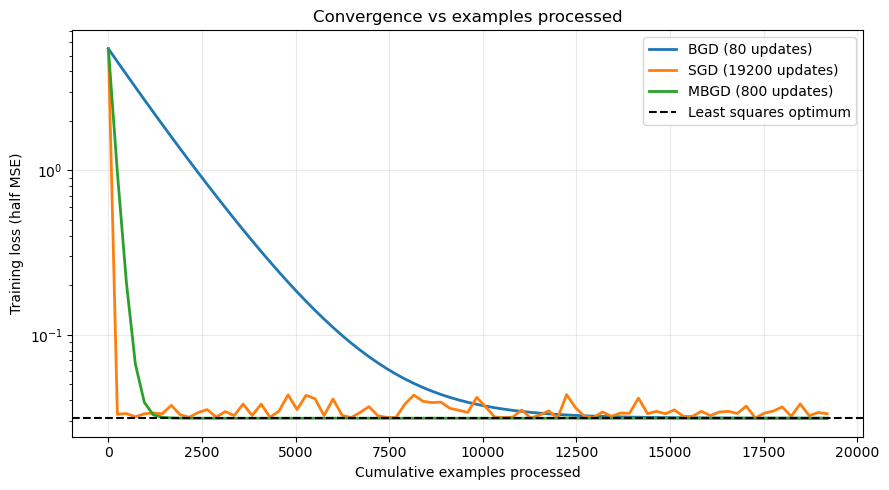

In [23]:
fig, ax = plt.subplots(figsize=(9, 5))
for name, model in models.items():
    x_axis = np.arange(epochs + 1) * len(y_train)
    ax.plot(x_axis, model.history, linewidth=2, label=f'{name} ({model.updates} updates)')
ax.axhline(optimal_loss, color='black', linestyle='--', label='Least squares optimum')
ax.set(xlabel='Cumulative examples processed', ylabel='Training loss (half MSE)', title='Convergence vs examples processed')
ax.set_yscale('log')
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Numerical gradient check

Finite differences validate the analytical full-batch gradient used by BGD (and by MBGD on each batch).

In [26]:
theta_check = np.array([0.7, -0.3])
eps = 1e-6
numeric = np.empty_like(theta_check)
for j in range(len(theta_check)):
    step = np.zeros_like(theta_check)
    step[j] = eps
    numeric[j] = (loss(X_train, y_train, theta_check + step) - loss(X_train, y_train, theta_check - step)) / (2 * eps)
analytic = full_gradient(X_train, y_train, theta_check)
print('Analytic gradient:', analytic)
print('Numeric gradient: ', numeric)
assert np.allclose(analytic, numeric, atol=1e-7, rtol=1e-6)
print('PASS: finite-difference gradient check')

Analytic gradient: [-2.10002296 -1.5061138 ]
Numeric gradient:  [-2.10002296 -1.5061138 ]
PASS: finite-difference gradient check
